In [36]:
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
df = pd.read_csv("/content/drive/MyDrive/ratings.csv", usecols=['userId', 'movieId', 'rating'], dtype="float")

ratings = df.to_numpy()[:1000000]


In [38]:
len(ratings)

1000000

In [39]:
def user_to_index():
  user_to_index = {}
  index = 0
  for row in ratings:
    user_id = row[0]
    user_id = int(user_id)
    if user_id not in user_to_index:
      user_to_index[user_id] = index
      index += 1
  return user_to_index

user_to_index = user_to_index()
print("User 3:", user_to_index[3])

User 3: 2


In [40]:
def index_to_user():
  index_to_user = []
  for user_id, index in user_to_index.items():
    index_to_user.append(user_id)
  return index_to_user

index_to_user = index_to_user()
print("Index 2:", index_to_user[2])



Index 2: 3


In [41]:
def item_to_index():
  item_to_index = {}
  index = 0
  for row in ratings:
    item_id = row[1]
    item_id = int(item_id)
    if item_id not in item_to_index:
      item_to_index[item_id] = index
      index += 1
  return item_to_index

item_to_index = item_to_index()
print("Item 25:", item_to_index[25])

Item 25: 1


In [42]:
print(item_to_index[3921])

17433


In [43]:
def index_to_item():
  index_to_item = []
  for item_id, index in item_to_index.items():
    index_to_item.append(item_id)
  return index_to_item

index_to_item = index_to_item()
print("Index 1:", index_to_item[1])

Index 1: 25


In [44]:
index_to_item[:10]

[17, 25, 29, 30, 32, 34, 36, 80, 110, 111]

In [45]:
rating_values = ratings[:,2].astype(float)

unique_rating, rating_count = np.unique(
    rating_values,
    return_counts=True
)

In [46]:
def save_svg(filename):
    plt.savefig(filename + ".svg", format="svg", bbox_inches="tight")

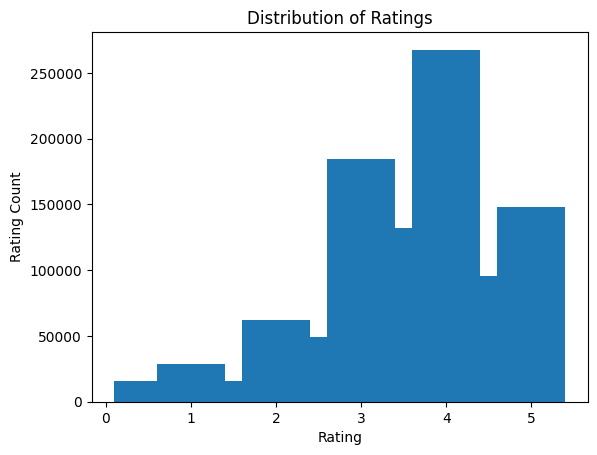

In [47]:
import matplotlib.pyplot as plt

plt.bar(unique_rating, rating_count)
plt.xlabel("Rating")
plt.ylabel("Rating Count")
plt.title("Distribution of Ratings")
save_svg("Ratings_distribution")
plt.show()

In [48]:
def rating_by_user(ratings):
  ratings_by_user = [[] for _ in range(len(user_to_index))]
  for row in ratings:
    user_id = row[0]
    item_id = row[1]
    rating = row[2]
    rating = float(rating)

    item_index  = item_to_index[item_id]
    ratings_by_user[user_to_index[user_id]].append((item_index, rating))

  return ratings_by_user

rating_by_user = rating_by_user(ratings)

In [49]:
def rating_by_item(ratings):
  ratings_by_item = [[] for _ in range(len(item_to_index))]
  for row in ratings:
    user_id = row[0]
    item_id = row[1]
    rating = row[2]
    rating = float(rating)

    user_index = user_to_index[user_id]
    ratings_by_item[item_to_index[item_id]].append((user_index, rating))

  return ratings_by_item

rating_by_item = rating_by_item(ratings)

In [50]:
number_of_ratings_per_user = []
for user_index, ratings in enumerate(rating_by_user):
  number_of_ratings_per_user.append(len(rating_by_user[user_index]))

user_counts, user_frequency = np.unique(
    number_of_ratings_per_user,
    return_counts=True
)

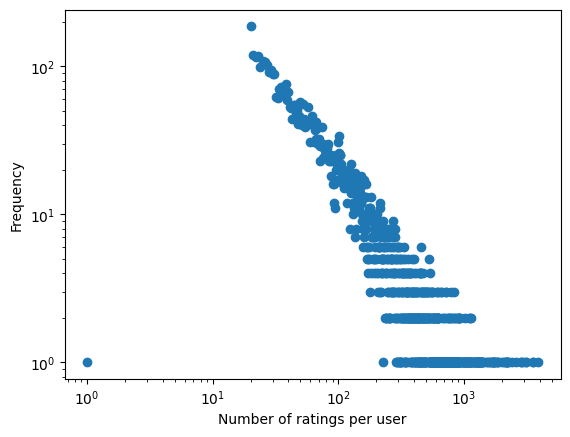

In [51]:
import matplotlib.pyplot as plt

plt.scatter(user_counts, user_frequency)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of ratings per user")
plt.ylabel("Frequency")
save_svg("user_pl")
plt.show()

In [52]:
number_of_ratings_per_item = []
for item_index, ratings in enumerate(rating_by_item):
  number_of_ratings_per_item.append(len(rating_by_item[item_index]))

item_counts, item_frequency = np.unique(
    number_of_ratings_per_item,
    return_counts=True
)

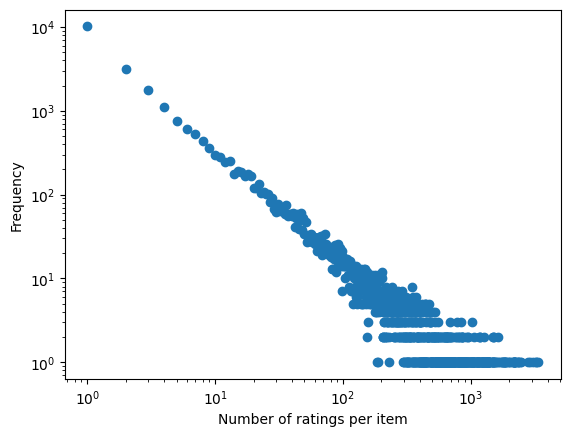

In [53]:
plt.scatter(item_counts, item_frequency)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of ratings per item")
plt.ylabel("Frequency")
save_svg("Item_pl")
plt.show()

In [54]:
ratings_data = pd.read_csv("/content/drive/MyDrive/ratings.csv", usecols=['userId', 'movieId', 'rating'], dtype="float")

ratings_data.to_numpy()
ratings_data = ratings_data[:1000000]
ratings_data = np.array(ratings_data)

In [55]:
len(user_to_index)

6503

In [56]:

import numpy as np
import matplotlib.pyplot as plt
from itertools import product

# ratings_data columns: user_id, item_id, rating
rng = np.random.default_rng(42)

n_users = len(user_to_index)
n_items = len(item_to_index)

# Each split contains [index, rating] pairs.
user_train = [[] for _ in range(n_users)]
user_val = [[] for _ in range(n_users)]
user_test = [[] for _ in range(n_users)]

item_train = [[] for _ in range(n_items)]
item_val = [[] for _ in range(n_items)]
item_test = [[] for _ in range(n_items)]

# Assign each rating to exactly one split.
assignments = rng.random(len(ratings_data))

for i, row in enumerate(ratings_data):
    user_id = int(row[0])
    item_id = int(row[1])
    rating = float(row[2])

    m = user_to_index[user_id]
    n = item_to_index[item_id]

    if assignments[i] < 0.80:
        user_train[m].append((n, rating))
        item_train[n].append((m, rating))

    elif assignments[i] < 0.90:
        user_val[m].append((n, rating))
        item_val[n].append((m, rating))

    else:
        user_test[m].append((n, rating))
        item_test[n].append((m, rating))

# Confirm that all splits contain the same ratings
# whether grouped by user or by item.
n_train = sum(map(len, user_train))
n_val = sum(map(len, user_val))
n_test = sum(map(len, user_test))

assert n_train == sum(map(len, item_train))
assert n_val == sum(map(len, item_val))
assert n_test == sum(map(len, item_test))
assert n_train + n_val + n_test == len(ratings_data)

print(f"Training ratings:   {n_train:,}")
print(f"Validation ratings: {n_val:,}")
print(f"Test ratings:       {n_test:,}")

# Estimate the global mean from training ratings only.
train_ratings = np.array(
    [rating for ratings in user_train for _, rating in ratings],
    dtype=np.float64
)

global_average = train_ratings.mean()

print(f"Training global average: {global_average:.4f}")


Training ratings:   799,857
Validation ratings: 99,963
Test ratings:       100,180
Training global average: 3.5652


In [57]:

import numpy as np

lam = 0.1
gamma = 0.5
tau = 0.5
epochs = 20

n_users = len(user_train)
n_items = len(item_train)

user_bias = np.zeros(n_users, dtype=np.float64)
item_bias = np.zeros(n_items, dtype=np.float64)

train_ratings = [
    rating
    for user_ratings in user_train
    for _, rating in user_ratings
]

global_average = np.mean(train_ratings)

train_loss = []
test_loss = []
train_rmse = []
test_rmse = []


def calculate_sse(ratings_by_user):
    squared_error = 0.0
    count = 0

    for m, user_ratings in enumerate(ratings_by_user):
        for n, rating in user_ratings:

            prediction = (
                global_average
                + user_bias[m]
                + item_bias[n]
            )

            error = rating - prediction
            squared_error += error ** 2
            count += 1

    return squared_error, count


for epoch in range(epochs):

    # Update user biases
    for m, user_ratings in enumerate(user_train):

        numerator = 0.0
        count = len(user_ratings)

        for n, rating in user_ratings:
            numerator += lam * (
                rating - global_average - item_bias[n]
            )

        denominator = lam * count + gamma

        user_bias[m] = (
            numerator / denominator if denominator > 0 else 0.0
        )

    # Update item biases
    for n, item_ratings in enumerate(item_train):

        numerator = 0.0
        count = len(item_ratings)

        for m, rating in item_ratings:
            numerator += lam * (
                rating - global_average - user_bias[m]
            )

        denominator = lam * count + tau

        item_bias[n] = (
            numerator / denominator if denominator > 0 else 0.0
        )

    # Evaluate training and test data
    train_sse, train_count = calculate_sse(
        user_train
    )

    test_sse, test_count = calculate_sse(
        user_test
    )

    if train_count == 0 or test_count == 0:
        raise ValueError("Training and test sets must be non-empty.")

    train_mse = train_sse / train_count
    test_mse = test_sse / test_count

    train_rmse_value = np.sqrt(train_mse)
    test_rmse_value = np.sqrt(test_mse)

    regularization = (
        gamma * np.sum(user_bias ** 2)
        + tau * np.sum(item_bias ** 2)
    )

    objective = lam * train_sse + regularization

    train_loss.append(train_mse)
    test_loss.append(test_mse)
    train_rmse.append(train_rmse_value)
    test_rmse.append(test_rmse_value)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_mse:.4f} | "
        f"Test Loss: {test_mse:.4f} | "
        f"Train RMSE: {train_rmse_value:.4f} | "
        f"Test RMSE: {test_rmse_value:.4f} | "
        f"Objective: {objective:.4f}"
    )


Epoch 1/20 | Train Loss: 0.7395 | Test Loss: 0.7651 | Train RMSE: 0.8599 | Test RMSE: 0.8747 | Objective: 60799.7598
Epoch 2/20 | Train Loss: 0.7192 | Test Loss: 0.7442 | Train RMSE: 0.8481 | Test RMSE: 0.8627 | Objective: 59228.9840
Epoch 3/20 | Train Loss: 0.7179 | Test Loss: 0.7427 | Train RMSE: 0.8473 | Test RMSE: 0.8618 | Objective: 59137.5453
Epoch 4/20 | Train Loss: 0.7176 | Test Loss: 0.7425 | Train RMSE: 0.8471 | Test RMSE: 0.8617 | Objective: 59109.9838
Epoch 5/20 | Train Loss: 0.7175 | Test Loss: 0.7423 | Train RMSE: 0.8471 | Test RMSE: 0.8616 | Objective: 59090.6814
Epoch 6/20 | Train Loss: 0.7174 | Test Loss: 0.7422 | Train RMSE: 0.8470 | Test RMSE: 0.8615 | Objective: 59075.3666
Epoch 7/20 | Train Loss: 0.7174 | Test Loss: 0.7421 | Train RMSE: 0.8470 | Test RMSE: 0.8615 | Objective: 59062.9822
Epoch 8/20 | Train Loss: 0.7173 | Test Loss: 0.7421 | Train RMSE: 0.8469 | Test RMSE: 0.8614 | Objective: 59052.9291
Epoch 9/20 | Train Loss: 0.7172 | Test Loss: 0.7420 | Train RMSE

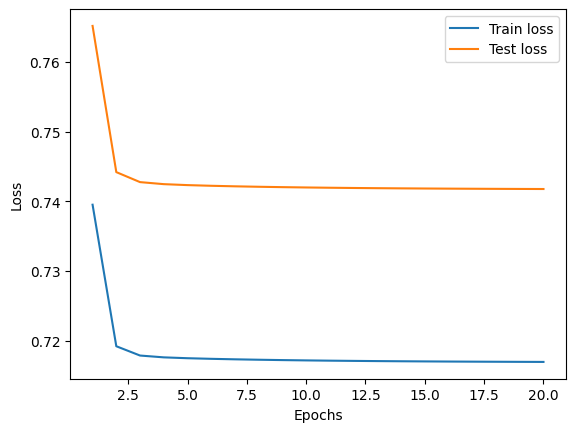

In [58]:
epoch_list = []
[epoch_list.append(epoch+1) for epoch in range(epochs)]

plt.plot(epoch_list, train_loss, label="Train loss")
plt.plot(epoch_list, test_loss, label="Test loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
save_svg("1m_bias_pl")
plt.show()

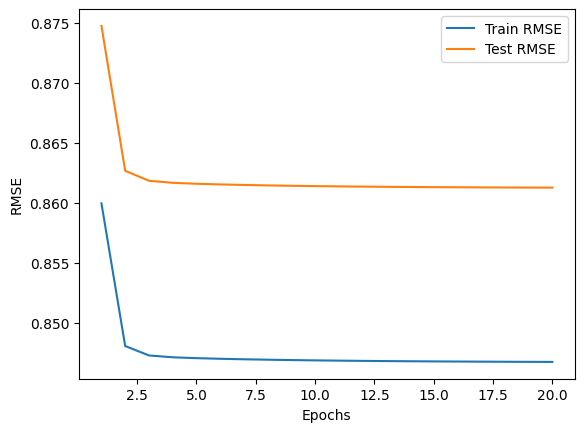

In [59]:
plt.plot(epoch_list, train_rmse, label="Train RMSE")
plt.plot(epoch_list, test_rmse, label="Test RMSE")
plt.xlabel("Epochs")
plt.ylabel("RMSE")
plt.legend()
save_svg("1m_rmse_pl")
plt.show()

In [60]:
def calculate_sse(ratings_by_user, u_bias, i_bias,
                  U_mat, V_mat, global_average):
    squared_error = 0.0
    count = 0

    for m, user_ratings in enumerate(ratings_by_user):
        for n, rating in user_ratings:
            prediction = (
                global_average
                + u_bias[m]
                + i_bias[n]
                + np.dot(U_mat[m], V_mat[n])
            )

            error = rating - prediction
            squared_error += error ** 2
            count += 1

    return squared_error, count

def train_als_model(
    k_dim,
    lam_val,
    gamma_val,
    tau_val,
    u_reg_val,
    v_reg_val,
    num_epochs=10,
    seed=42
):
    u_bias = np.zeros(n_users, dtype=np.float64)
    i_bias = np.zeros(n_items, dtype=np.float64)

    local_rng = np.random.default_rng(seed)

    U_mat = local_rng.normal(
        0, 0.01, (n_users, k_dim)
    )
    V_mat = local_rng.normal(
        0, 0.01, (n_items, k_dim)
    )

    I_mat = np.eye(k_dim, dtype=np.float64)

    for epoch in range(num_epochs):

        # Update user biases.
        for m, user_ratings in enumerate(user_train):
            if not user_ratings:
                u_bias[m] = 0.0
                continue

            numerator = 0.0

            for n, rating in user_ratings:
                dot = np.dot(U_mat[m], V_mat[n])

                numerator += lam_val * (
                    rating - global_average
                    - i_bias[n] - dot
                )

            denominator = (
                lam_val * len(user_ratings) + gamma_val
            )
            u_bias[m] = numerator / denominator

        # Update item biases.
        for n, item_ratings in enumerate(item_train):
            if not item_ratings:
                i_bias[n] = 0.0
                continue

            numerator = 0.0

            for m, rating in item_ratings:
                dot = np.dot(U_mat[m], V_mat[n])

                numerator += lam_val * (
                    rating - global_average
                    - u_bias[m] - dot
                )

            denominator = (
                lam_val * len(item_ratings) + tau_val
            )
            i_bias[n] = numerator / denominator

        # Update user latent factors.
        for m, user_ratings in enumerate(user_train):
            if not user_ratings:
                U_mat[m, :] = 0.0
                continue

            item_indices = np.array(
                [n for n, _ in user_ratings], dtype=int
            )
            ratings = np.array(
                [r for _, r in user_ratings], dtype=np.float64
            )

            V_items = V_mat[item_indices]

            residual = (
                ratings - global_average
                - u_bias[m] - i_bias[item_indices]
            )

            A = (
                lam_val * (V_items.T @ V_items)
                + u_reg_val * I_mat
            )
            b = lam_val * (V_items.T @ residual)

            U_mat[m] = np.linalg.solve(A, b)

        # Update item latent factors.
        for n, item_ratings in enumerate(item_train):
            if not item_ratings:
                V_mat[n, :] = 0.0
                continue

            user_indices = np.array(
                [m for m, _ in item_ratings], dtype=int
            )
            ratings = np.array(
                [r for _, r in item_ratings], dtype=np.float64
            )

            U_users = U_mat[user_indices]

            residual = (
                ratings - global_average
                - u_bias[user_indices] - i_bias[n]
            )

            A = (
                lam_val * (U_users.T @ U_users)
                + v_reg_val * I_mat
            )
            b = lam_val * (U_users.T @ residual)

            V_mat[n] = np.linalg.solve(A, b)

    # Evaluate using the SAME fitted parameters.
    train_sse, train_count = calculate_sse(
        user_train, u_bias, i_bias,
        U_mat, V_mat, global_average
    )

    val_sse, val_count = calculate_sse(
        user_val, u_bias, i_bias,
        U_mat, V_mat, global_average
    )

    train_rmse = (
        np.sqrt(train_sse / train_count)
        if train_count else float("inf")
    )
    val_rmse = (
        np.sqrt(val_sse / val_count)
        if val_count else float("inf")
    )

    return {
        "train_rmse": train_rmse,
        "val_rmse": val_rmse,
        "U": U_mat,
        "V": V_mat,
        "user_bias": u_bias,
        "item_bias": i_bias,
    }


In [61]:

param_grid = {
    "lam": [0.01, 0.1, 1.0],
    "gamma": [0.1, 0.5],
    "tau": [0.1, 0.5],
}

best_val_rmse = float("inf")
best_params = None

print("Hyperparameter search")

for lam_val, gamma_val, tau_val in product(
    param_grid["lam"],
    param_grid["gamma"],
    param_grid["tau"]
):
    result = train_als_model(
        k_dim=10,
        lam_val=lam_val,
        gamma_val=gamma_val,
        tau_val=tau_val,
        u_reg_val=0.1,
        v_reg_val=0.1,
        num_epochs=5,
        seed=42
    )

    print(
        f"lambda={lam_val}, gamma={gamma_val}, "
        f"tau={tau_val} | "
        f"Train RMSE={result['train_rmse']:.4f} | "
        f"Validation RMSE={result['val_rmse']:.4f}"
    )

    if result["val_rmse"] < best_val_rmse:
        best_val_rmse = result["val_rmse"]

        best_params = {
            "lam": lam_val,
            "gamma": gamma_val,
            "tau": tau_val,
        }

print("\nBest parameters:", best_params)
print(f"Best validation RMSE: {best_val_rmse:.4f}")


Hyperparameter search
lambda=0.01, gamma=0.1, tau=0.1 | Train RMSE=0.7226 | Validation RMSE=0.8278
lambda=0.01, gamma=0.1, tau=0.5 | Train RMSE=0.7277 | Validation RMSE=0.8294
lambda=0.01, gamma=0.5, tau=0.1 | Train RMSE=0.7280 | Validation RMSE=0.8319
lambda=0.01, gamma=0.5, tau=0.5 | Train RMSE=0.7333 | Validation RMSE=0.8337
lambda=0.1, gamma=0.1, tau=0.1 | Train RMSE=0.6593 | Validation RMSE=0.8754
lambda=0.1, gamma=0.1, tau=0.5 | Train RMSE=0.6616 | Validation RMSE=0.8762
lambda=0.1, gamma=0.5, tau=0.1 | Train RMSE=0.6598 | Validation RMSE=0.8757
lambda=0.1, gamma=0.5, tau=0.5 | Train RMSE=0.6620 | Validation RMSE=0.8764
lambda=1.0, gamma=0.1, tau=0.1 | Train RMSE=0.6559 | Validation RMSE=0.9947
lambda=1.0, gamma=0.1, tau=0.5 | Train RMSE=0.6563 | Validation RMSE=0.9942
lambda=1.0, gamma=0.5, tau=0.1 | Train RMSE=0.6560 | Validation RMSE=0.9946
lambda=1.0, gamma=0.5, tau=0.5 | Train RMSE=0.6563 | Validation RMSE=0.9941

Best parameters: {'lam': 0.01, 'gamma': 0.1, 'tau': 0.1}
Best

k=2 | Train RMSE=0.7977 | Validation RMSE=0.8369
k=5 | Train RMSE=0.7575 | Validation RMSE=0.8240
k=12 | Train RMSE=0.7011 | Validation RMSE=0.8200
k=20 | Train RMSE=0.6579 | Validation RMSE=0.8277
k=40 | Train RMSE=0.5815 | Validation RMSE=0.8476


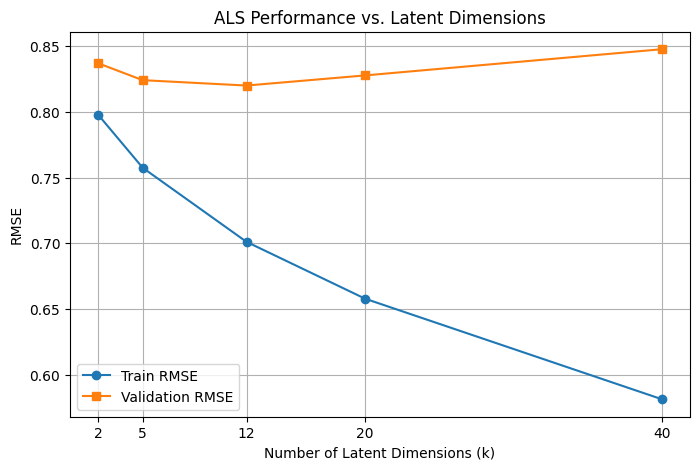

In [62]:

latent_dim_candidates = [2, 5, 12, 20, 40]

dim_train_rmse = []
dim_val_rmse = []

lam_opt = best_params["lam"]
gamma_opt = best_params["gamma"]
tau_opt = best_params["tau"]

for k_val in latent_dim_candidates:
    result = train_als_model(
        k_dim=k_val,
        lam_val=lam_opt,
        gamma_val=gamma_opt,
        tau_val=tau_opt,
        u_reg_val=0.1,
        v_reg_val=0.1,
        num_epochs=10,
        seed=42
    )

    dim_train_rmse.append(result["train_rmse"])
    dim_val_rmse.append(result["val_rmse"])

    print(
        f"k={k_val} | "
        f"Train RMSE={result['train_rmse']:.4f} | "
        f"Validation RMSE={result['val_rmse']:.4f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(
    latent_dim_candidates, dim_train_rmse,
    marker="o", label="Train RMSE"
)
plt.plot(
    latent_dim_candidates, dim_val_rmse,
    marker="s", label="Validation RMSE"
)
plt.xlabel("Number of Latent Dimensions (k)")
plt.ylabel("RMSE")
plt.title("ALS Performance vs. Latent Dimensions")
plt.xticks(latent_dim_candidates)
plt.legend()
plt.grid(True)
save_svg("1m_latent_dim_pl")
plt.show()


In [63]:

# Select k using validation RMSE
best_k = latent_dim_candidates[
    int(np.argmin(dim_val_rmse))
]

final_model = train_als_model(
    k_dim=best_k,
    lam_val=lam_opt,
    gamma_val=gamma_opt,
    tau_val=tau_opt,
    u_reg_val=0.1,
    v_reg_val=0.1,
    num_epochs=10,
    seed=42
)

test_sse, test_count = calculate_sse(
    user_test,
    final_model["user_bias"],
    final_model["item_bias"],
    final_model["U"],
    final_model["V"],
    global_average
)

test_rmse = (
    np.sqrt(test_sse / test_count)
    if test_count > 0 else float("inf")
)

print("\nFinal test evaluation")
print(f"Selected latent dimension: {best_k}")
print(f"Train RMSE: {final_model['train_rmse']:.4f}")
print(f"Validation RMSE: {final_model['val_rmse']:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")



Final test evaluation
Selected latent dimension: 12
Train RMSE: 0.7011
Validation RMSE: 0.8200
Test RMSE: 0.8165


In [64]:
full_train_loss = []
full_test_loss = []
full_train_rmse = []
full_test_rmse = []
def calculate_sse(ratings_by_user, u_bias, i_bias,
                  U_mat, V_mat, global_average):
    squared_error = 0.0
    count = 0

    for m, user_ratings in enumerate(ratings_by_user):
        for n, rating in user_ratings:
            prediction = (
                global_average
                + u_bias[m]
                + i_bias[n]
                + np.dot(U_mat[m], V_mat[n])
            )

            error = rating - prediction
            squared_error += error ** 2
            count += 1

    return squared_error, count

def train_als_model(
    k_dim,
    lam_val,
    gamma_val,
    tau_val,
    u_reg_val,
    v_reg_val,
    num_epochs,
    seed=42
):

    u_bias = np.zeros(n_users, dtype=np.float64)
    i_bias = np.zeros(n_items, dtype=np.float64)

    local_rng = np.random.default_rng(seed)

    U_mat = local_rng.normal(
        0, 0.01, (n_users, k_dim)
    )
    V_mat = local_rng.normal(
        0, 0.01, (n_items, k_dim)
    )

    I_mat = np.eye(k_dim, dtype=np.float64)

    for epoch in range(num_epochs):

        # Update user biases.
        for m, user_ratings in enumerate(user_train):
            if not user_ratings:
                u_bias[m] = 0.0
                continue

            numerator = 0.0

            for n, rating in user_ratings:
                dot = np.dot(U_mat[m], V_mat[n])

                numerator += lam_val * (
                    rating - global_average
                    - i_bias[n] - dot
                )

            denominator = (
                lam_val * len(user_ratings) + gamma_val
            )
            u_bias[m] = numerator / denominator

        # Update item biases.
        for n, item_ratings in enumerate(item_train):
            if not item_ratings:
                i_bias[n] = 0.0
                continue

            numerator = 0.0

            for m, rating in item_ratings:
                dot = np.dot(U_mat[m], V_mat[n])

                numerator += lam_val * (
                    rating - global_average
                    - u_bias[m] - dot
                )

            denominator = (
                lam_val * len(item_ratings) + tau_val
            )
            i_bias[n] = numerator / denominator

        # Update user latent factors.
        for m, user_ratings in enumerate(user_train):
            if not user_ratings:
                U_mat[m, :] = 0.0
                continue

            item_indices = np.array(
                [n for n, _ in user_ratings], dtype=int
            )
            ratings = np.array(
                [r for _, r in user_ratings], dtype=np.float64
            )

            V_items = V_mat[item_indices]

            residual = (
                ratings - global_average
                - u_bias[m] - i_bias[item_indices]
            )

            A = (
                lam_val * (V_items.T @ V_items)
                + u_reg_val * I_mat
            )
            b = lam_val * (V_items.T @ residual)

            U_mat[m] = np.linalg.solve(A, b)

        # Update item latent factors.
        for n, item_ratings in enumerate(item_train):
            if not item_ratings:
                V_mat[n, :] = 0.0
                continue

            user_indices = np.array(
                [m for m, _ in item_ratings], dtype=int
            )
            ratings = np.array(
                [r for _, r in item_ratings], dtype=np.float64
            )

            U_users = U_mat[user_indices]

            residual = (
                ratings - global_average
                - u_bias[user_indices] - i_bias[n]
            )

            A = (
                lam_val * (U_users.T @ U_users)
                + v_reg_val * I_mat
            )
            b = lam_val * (U_users.T @ residual)

            V_mat[n] = np.linalg.solve(A, b)

      # Evaluate training and test data
        train_sse, train_count = calculate_sse(user_train, u_bias, i_bias,
                            U_mat, V_mat, global_average
                            )

        test_sse, test_count = calculate_sse(user_test, u_bias, i_bias,
                            U_mat, V_mat, global_average
                            )

        if train_count == 0 or test_count == 0:
            raise ValueError("Training and test sets must be non-empty.")

        train_mse = train_sse / train_count
        test_mse = test_sse / test_count

        train_rmse_value = np.sqrt(train_mse)
        test_rmse_value = np.sqrt(test_mse)

        regularization = (
            gamma * np.sum(user_bias ** 2)
            + tau * np.sum(item_bias ** 2)
        )

        objective = lam * train_sse + regularization

        full_train_loss.append(train_mse)
        full_test_loss.append(test_mse)
        full_train_rmse.append(train_rmse_value)
        full_test_rmse.append(test_rmse_value)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_mse:.4f} | "
            f"Test Loss: {test_mse:.4f} | "
            f"Train RMSE: {train_rmse_value:.4f} | "
            f"Test RMSE: {test_rmse_value:.4f} | "
            f"Objective: {objective:.4f}"
        )



In [65]:
# Train with best hyperparameters
train_als_model(k_dim=12,
                lam_val=0.01,
                gamma_val=0.1,
                tau_val=0.1,
                u_reg_val=0.1,
                v_reg_val=0.1,
                num_epochs=20,
                seed=42)

Epoch 1/20 | Train Loss: 0.7445 | Test Loss: 0.7652 | Train RMSE: 0.8628 | Test RMSE: 0.8748 | Objective: 61211.6304
Epoch 2/20 | Train Loss: 0.6148 | Test Loss: 0.7202 | Train RMSE: 0.7841 | Test RMSE: 0.8487 | Objective: 50837.0359
Epoch 3/20 | Train Loss: 0.5361 | Test Loss: 0.6983 | Train RMSE: 0.7322 | Test RMSE: 0.8356 | Objective: 44541.1789
Epoch 4/20 | Train Loss: 0.5142 | Test Loss: 0.6853 | Train RMSE: 0.7171 | Test RMSE: 0.8278 | Objective: 42793.9194
Epoch 5/20 | Train Loss: 0.5045 | Test Loss: 0.6776 | Train RMSE: 0.7103 | Test RMSE: 0.8232 | Objective: 42013.7772
Epoch 6/20 | Train Loss: 0.4992 | Test Loss: 0.6731 | Train RMSE: 0.7065 | Test RMSE: 0.8204 | Objective: 41590.8224
Epoch 7/20 | Train Loss: 0.4960 | Test Loss: 0.6703 | Train RMSE: 0.7043 | Test RMSE: 0.8187 | Objective: 41337.2713
Epoch 8/20 | Train Loss: 0.4940 | Test Loss: 0.6685 | Train RMSE: 0.7028 | Test RMSE: 0.8176 | Objective: 41174.4220
Epoch 9/20 | Train Loss: 0.4926 | Test Loss: 0.6674 | Train RMSE

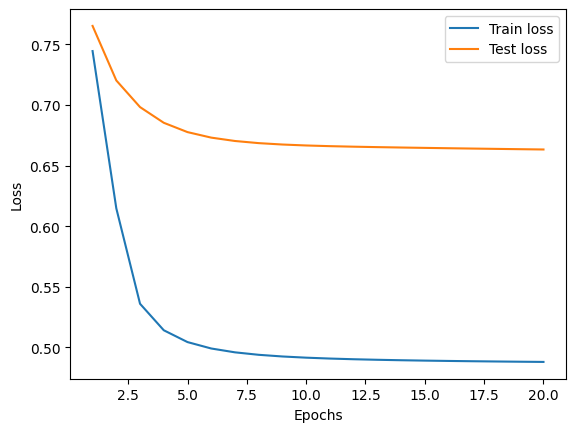

In [66]:
epoch_array = []
for epoch in range(epochs):
  epoch_array.append(epoch + 1)
plt.plot(epoch_array, full_train_loss, label="Train loss")
plt.plot(epoch_array, full_test_loss, label="Test loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
save_svg("1m_full_loss")
plt.show()

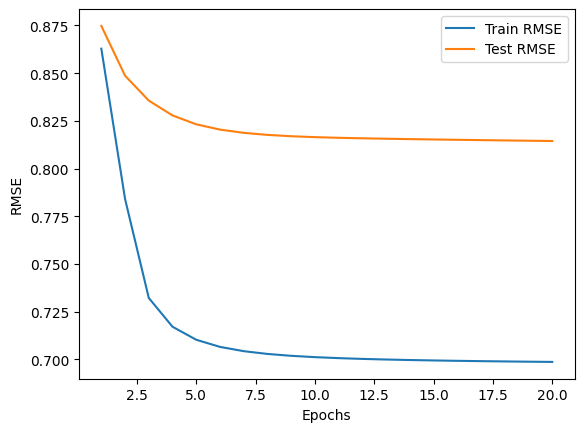

In [67]:
plt.plot(epoch_array, full_train_rmse, label="Train RMSE")
plt.plot(epoch_array, full_test_rmse, label="Test RMSE")
plt.xlabel("Epochs")
plt.ylabel("RMSE")
plt.legend()
save_svg("1m_full_rmse")
plt.show()


In [68]:
train_count = sum(len(user) for user in user_train)
test_count = sum(len(user) for user in user_test)
print(train_count)
print(test_count)
print(train_count + test_count)

799857
100180
900037
